In [1]:
import sys 
import os
from datetime import datetime
today = datetime.now().strftime("%Y-%m-%d")
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import hdf5plugin

import matplotlib.pyplot as plt
import seaborn as sns

# Add repo path to sys path (allows to access scripts and metadata from repo)
repo_path = os.path.split(os.getcwd())[0]
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts')

%reload_ext autoreload

/nfs/team205/vk8/mambaforge/envs/squidpy-env3/lib/python3.12/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/nfs/team205/vk8/mambaforge/envs/squidpy-env3/lib/python3.12/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/nfs/team205/vk8/mambaforge/envs/squidpy-env3/lib/python3.12/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/nfs/team205/vk8/mambaforge/envs/squidpy-env3/lib/python3.12/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/nfs/team205/vk8/mambaforge/envs/squidpy-env3/lib/python3.12/s

import scvi

In [2]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # to show output from all the lines in a cells
pd.set_option('display.max_column',None) # display all the columns in pandas
pd.options.display.max_rows = 100
import matplotlib
from matplotlib import rcParams
#rcParams['pdf.fonttype'] = 42
#sc.settings.set_figure_params(dpi = 150, color_map = 'RdPu', dpi_save = 150, vector_friendly = True, format = 'pdf')

In [3]:
# Define plot and path dirs
plot_path = os.path.join(repo_path, 'plots')
data_path = os.path.join(repo_path, 'data')
model_path = os.path.join(repo_path, 'models')
general_data_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/thymus_ageing_atlas/General_analysis/data'

In [4]:
sc.settings.set_figure_params(dpi = 150, color_map = 'RdPu', dpi_save = 150, vector_friendly = True, format = 'pdf')

# Load data

In [5]:
tecs_xen = ad.read_h5ad(f'/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/adata_xenium_TEC_2025-04-09.zarr')

In [6]:
sc.pp.normalize_total(tecs_xen, target_sum = 1e4)
sc.pp.log1p(tecs_xen)

In [7]:
general_mrkrs = ['PTPRC', 'CD3G', 
               'HOXA9', 
               'HES1', #DN
               'RORC', #DP
               'CCR9',
              'PDCD1', #CD8aa
              'CD8A', 'CD8B', 
              'CD4', 'CD40LG', 
              'CRTAM', 'ANXA1', #memory
             'FOXP3', 'DHRS3', 
               'TRDC', #gama-delta 
              'EOMES', 'KLRD1', # NK cells
              'TNFSF11', # ILC
              'CD19', 'VPREB1', # pre-pro B cells
              'IGHD', 'IGHA1', 'IGHG1', 
              'CLEC9A', 'CLEC10A', 
              'LAMP3', 
             'LILRA4','S100A9', 'C1QA', 'TPSB2', 'ITGA2B', 'GYPA', 
              'PDGFRA', 'COLEC11', 'FBN1', 
              'RGS5', 'CDH5', 
               'LYVE1', 'EPCAM', 'PSMB11', 'DLK2', 'KRT14', 
               'CCL19', 'AIRE', 'KRT1', 'POU2F3',
               'MYOD1', 'NEUROG1']

general_mrkrs_lst = [i for i in general_mrkrs if i in tecs_xen.var_names]

In [8]:
tec_mrkrs_dict = {'pan-cTEC':['PSMB11', 'LY75', 'CCL25', 'HLA-DRA'],
        'cTEC\nsubtypes':['DLL4', 'TP53AIP1', 'TBATA'],
        'mcTEC':['DLK2','IGFBP5', 'IGFBP6','CCN2', 'CCL2',
              'KRT15', 'ITGA6', 'MKI67'],
        'pan-mTEC': ['EPCAM'],
        'mTECI': ['ASCL1','CCL21'],
        'mTECII': ['AIRE', 'FEZF2','CRIP1'], 
        'mTECIII':['SLPI', 'IVL', 'KRT10','CDKN2A'],
        'pan-neuro TEC': ['BEX1', 'NEUROD1'],
        'neuroTEC': ['NEUROG1', 'NEUROD4'], 
        'cilliated TEC': ['PCP4', 'FOXJ1'], 
        'myoTEC':['CHRNA1', 'MYOG', 'TTN'],
        'ionocytes':['FOXI1', 'CFTR'],
        'tuft cells':['POU2F3','PLCB2', 'TRPM5']}

for k,v in tec_mrkrs_dict.items():
    tec_mrkrs_dict[k] = [i for i in v if i in tecs_xen.var_names]

tec_mrkrs_lst = []
[tec_mrkrs_lst.extend(tec_mrkrs_dict[key]) for key in tec_mrkrs_dict.keys()]

ctec_markers = {'maturation': ['FOXN1', 'LY75', 'CD40', 'ACKR4'],
    'indT-dev': ['DLL4', 'IL7', 'CXCL12', 'CCL25'], 
                'positive_sel': ['PSMB11', 'CTSL', 'PRSS16'], 
                'mhc_ii': ['HLA-DMA', 'HLA-DMB', 'HLA-DOA', 'HLA-DOB', 'HLA-DPA1','HLA-DPB1',  'HLA-DQA1', 'HLA-DQA2',
 'HLA-DQB1', 'HLA-DQB1-AS1','HLA-DQB2', 'HLA-DRA', 'HLA-DRB1', 'HLA-DRB5'],
 'nurse_cells': ['CD4', 'CD8A', 'CD8B']
 }

for k,v in ctec_markers.items():
    ctec_markers[k] = [i for i in v if i in tecs_xen.var_names]

ctec_markers_lst = []
[ctec_markers_lst.extend(ctec_markers[key]) for key in ctec_markers.keys()]

fbs_mrkrs_dict = {'General': ['PDGFRA', 'VIM', 'DCN', 'PDPN', 'THY1'],
             'Interlobular (PI16 progenitor)': ['MFAP5', 'CD55', 'FBN1','SEMA3C', 'PI16','PCOLCE2'],
             'Intermediate': ['PTX3', 'FOSL1', 'TNFRSF12A', 'HMOX1', 'IL1RL1', 'HMGA1','MT1X'],
             'Parenchymal': ['C7', 'APOD', 'FBLN5', 'MFAP4', 'LUM', 'FMO2'],
             'Perilobular (progenitor)': ['COL15A1', 'COLEC11', 'ALDH1A2', 'PTN', 'HAND2', 'LAMC3'],
             'Medullary (antigen-presenting)': ['HLA-DRA',  'CD74', 'FRZB', 'CCL19', 'CCL21', 'IL33'],
             'FDC':['CXCL13', 'FDCSP'],
             'Adipose': ['CXCL12','PPARG', 'APOE', 'PPP1R1A', 'PLIN1', 'LIPE','CIDEA', 'MRAP', 'AQP7']
             }
for k,v in fbs_mrkrs_dict.items():
    fbs_mrkrs_dict[k] = [i for i in v if i in tecs_xen.var_names]

fb_mrkrs_lst = []
[fb_mrkrs_lst.extend(fbs_mrkrs_dict[key]) for key in fbs_mrkrs_dict.keys()]

[None, None, None, None, None, None, None, None, None, None, None, None, None]

[None, None, None, None, None]

[None, None, None, None, None, None, None, None]

In [9]:
from utils_vk8 import regen_embed, run_leiden

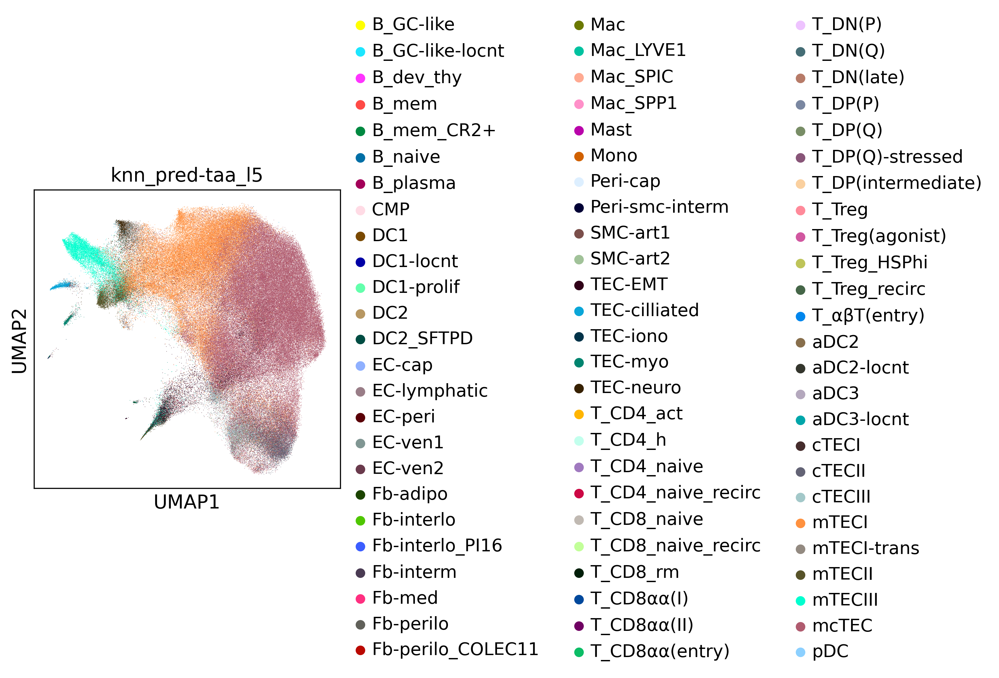

AnnData object with n_obs × n_vars = 245415 × 4993
    obs: 'sample', 'library', 'donor', 'chemistry_simple', 'age', 'sex', 'age_months', 'n_counts', 'taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1', 'taa_l0', 'batch', '_scvi_batch', '_scvi_labels', 'knn_pred-taa_l5', 'knn_pred-taa_l4', 'knn_pred-taa_l3', 'knn_pred-taa_l2', 'knn_pred-taa_l1', 'knn_pred-taa_l0', 'knn_uncert-taa_l5', 'knn_uncert-taa_l4', 'knn_uncert-taa_l3', 'knn_uncert-taa_l2', 'knn_uncert-taa_l1', 'knn_uncert-taa_l0'
    var: 'gene_name', 'gene_ids'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'batch_colors', 'neighbors', 'sample_colors', 'taa_l1_colors', 'taa_l3_colors', 'umap', 'log1p', 'knn_pred-taa_l5_colors'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [10]:
regen_embed(tecs_xen, anno2show = 'knn_pred-taa_l5')

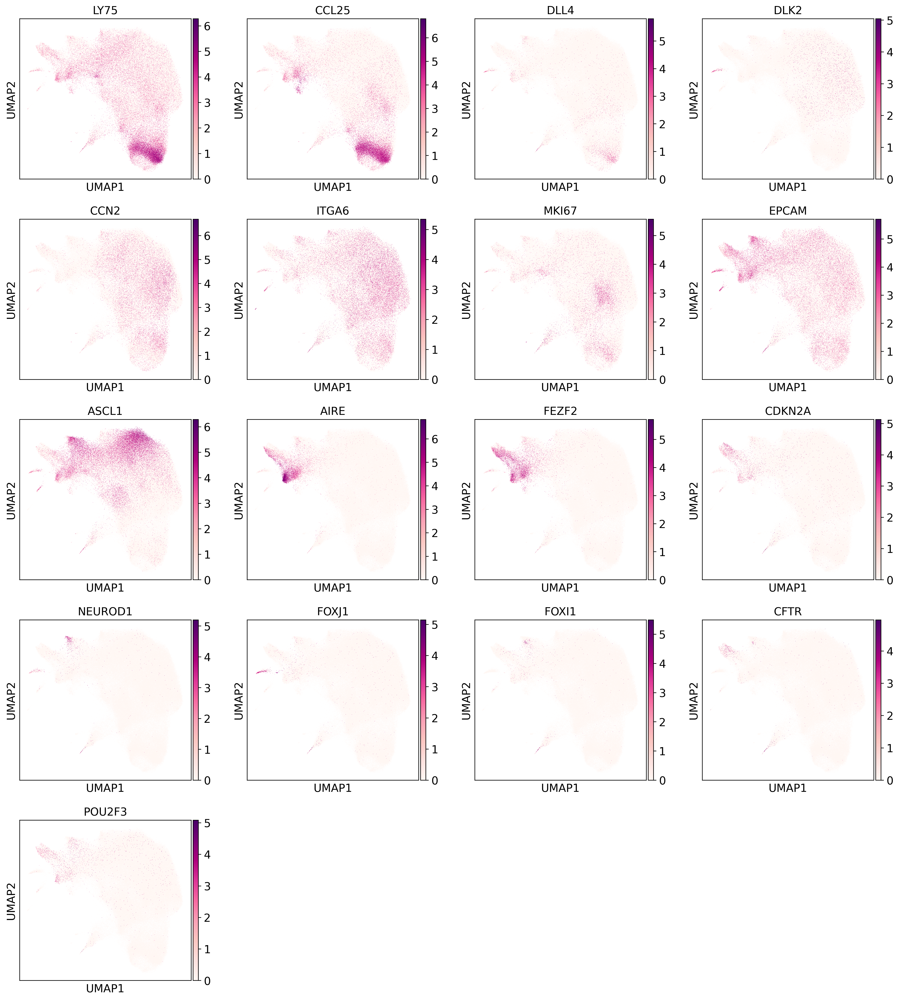

In [11]:
sc.pl.umap(tecs_xen, color = tec_mrkrs_lst, cmap = 'RdPu')

## Filter xenium cells 
- to remove cells with less than 70% probability of being TECs (taa_l3)
- to remove putative doublets according to taa_l5 

In [21]:
np.quantile (tecs_xen.obs['knn_uncert-taa_l1'], q = [0.05, 0.25, 0.5, 0.75, 0.8, 0.95])

array([0.00000000e+00, 0.00000000e+00, 1.11022302e-16, 1.33284637e-01,
       1.99851784e-01, 4.33421628e-01])

In [23]:
tecs_xen_filt = tecs_xen[tecs_xen.obs['knn_uncert-taa_l1']<0.3].copy()

In [24]:
np.mean (tecs_xen_filt.obs['knn_pred-taa_l5'].isin(['T_DP(Q)', 'T_CD8_naive',
                                                                        'B_mem_CR2+', 'Mac_SPIC', 'EC-ven2',
                                                                        'T_αβT(entry)', 'T_DP(P)', 'T_DP(Q)-stressed']))

0.00029436638803096923

In [25]:
tecs_xen_filt = tecs_xen_filt[~tecs_xen_filt.obs['knn_pred-taa_l5'].isin(['T_DP(Q)', 'T_CD8_naive',
                                                                        'B_mem_CR2+', 'Mac_SPIC', 'EC-ven2',
                                                                        'T_αβT(entry)', 'T_DP(P)', 'T_DP(Q)-stressed']),].copy()

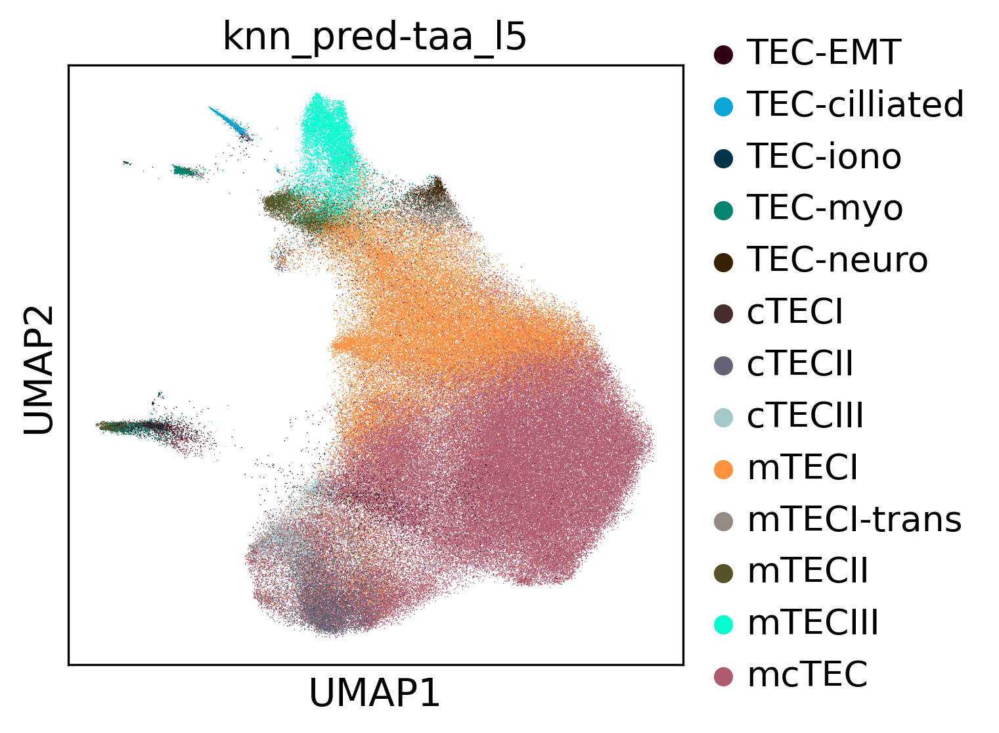

AnnData object with n_obs × n_vars = 213956 × 4993
    obs: 'sample', 'library', 'donor', 'chemistry_simple', 'age', 'sex', 'age_months', 'n_counts', 'taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1', 'taa_l0', 'batch', '_scvi_batch', '_scvi_labels', 'knn_pred-taa_l5', 'knn_pred-taa_l4', 'knn_pred-taa_l3', 'knn_pred-taa_l2', 'knn_pred-taa_l1', 'knn_pred-taa_l0', 'knn_uncert-taa_l5', 'knn_uncert-taa_l4', 'knn_uncert-taa_l3', 'knn_uncert-taa_l2', 'knn_uncert-taa_l1', 'knn_uncert-taa_l0'
    var: 'gene_name', 'gene_ids'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'batch_colors', 'neighbors', 'sample_colors', 'taa_l1_colors', 'taa_l3_colors', 'umap', 'log1p', 'knn_pred-taa_l5_colors'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [26]:
regen_embed(tecs_xen_filt, anno2show = 'knn_pred-taa_l5')

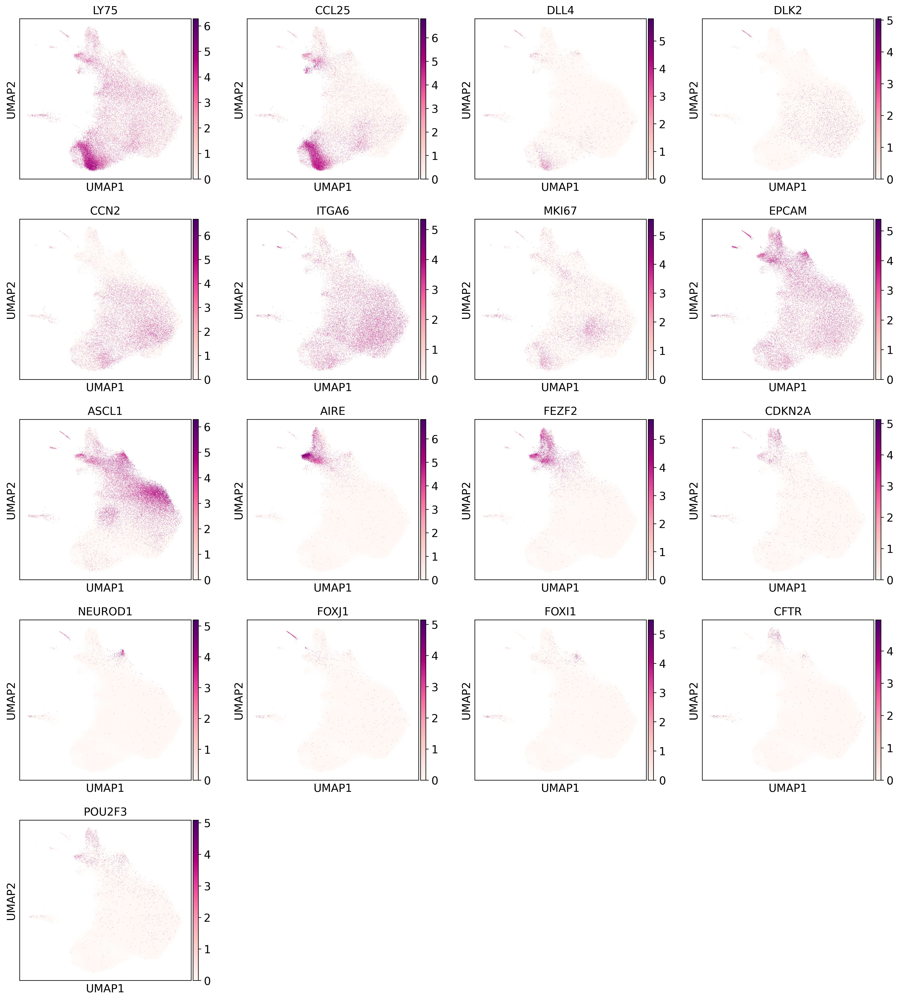

In [27]:
sc.pl.umap(tecs_xen_filt, color = tec_mrkrs_lst, cmap = 'RdPu')

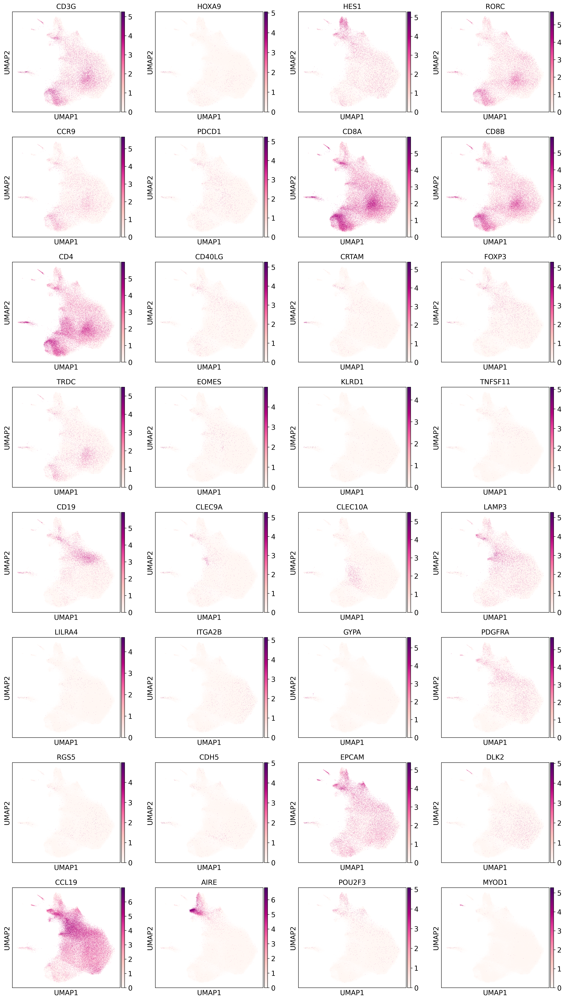

In [37]:
sc.pl.umap(tecs_xen_filt, color = general_mrkrs_lst, cmap = 'RdPu')

In [72]:
doubl_mrkrs = ['CD3G', 'CD8A', 'CD8B', 'CD4', 'CD19', 'CLEC9A', 'CLEC10A']

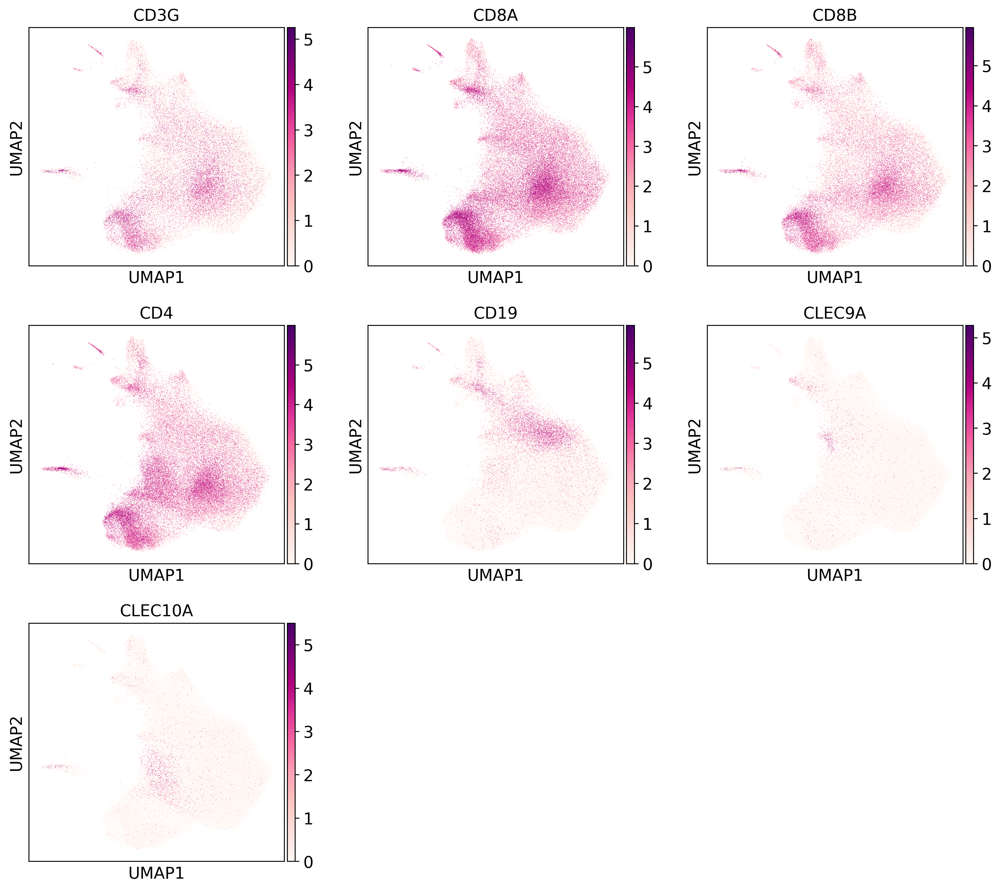

In [74]:
sc.pl.umap(tecs_xen_filt, color = doubl_mrkrs, cmap = 'RdPu', ncols = 3)

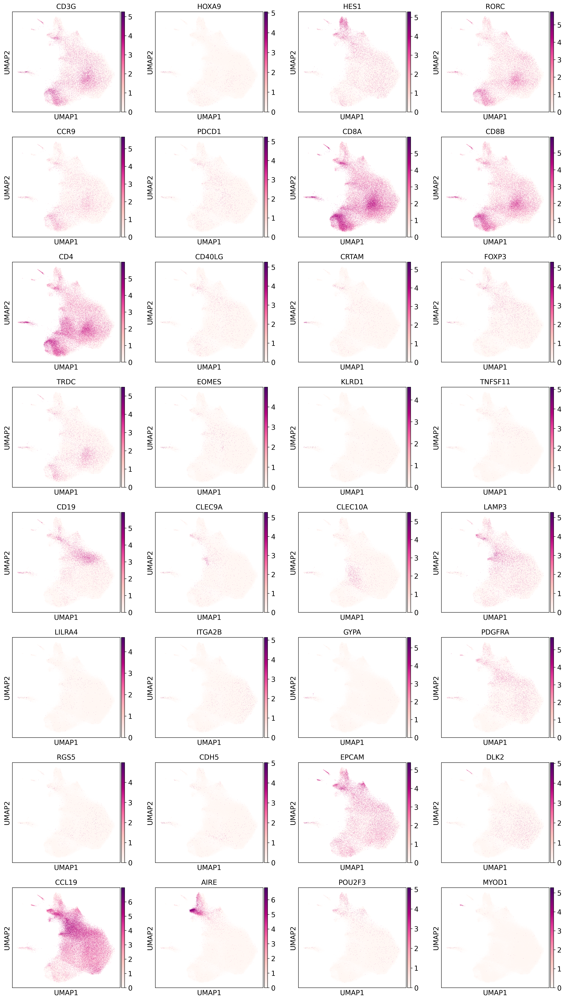

In [37]:
sc.pl.umap(tecs_xen_filt, color = general_mrkrs_lst, cmap = 'RdPu')

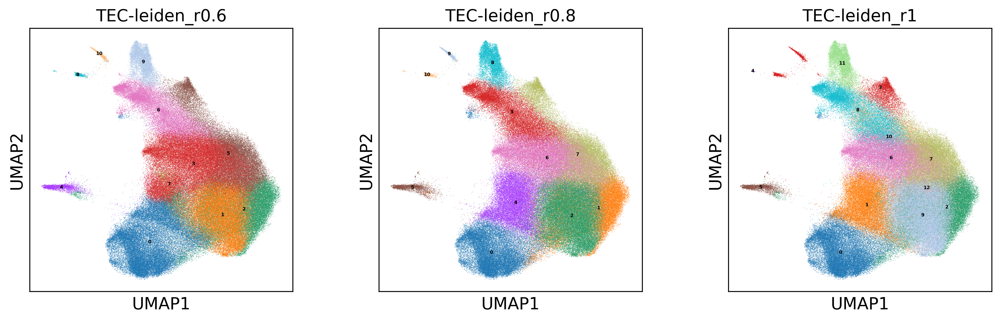

In [29]:
run_leiden(tecs_xen_filt, resolutions = [0.6, 0.8, 1], key_name = 'TEC')

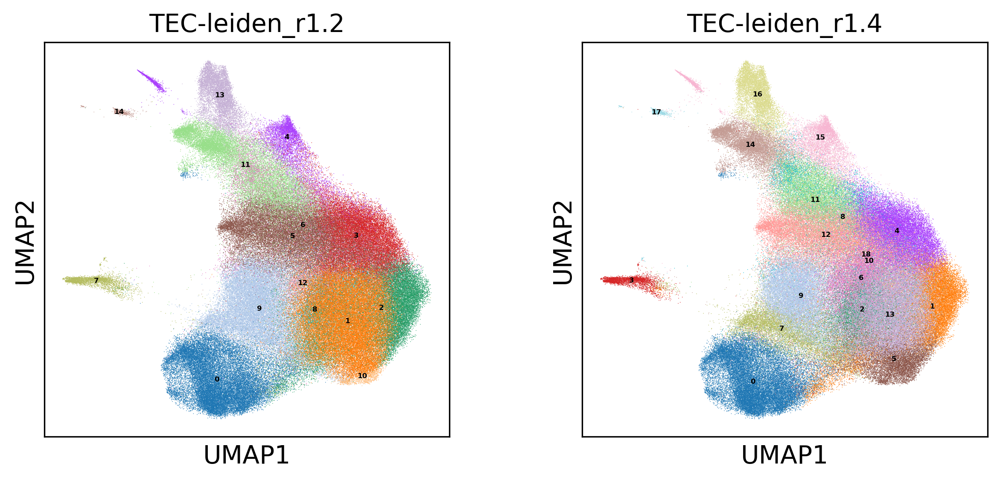

In [31]:
run_leiden(tecs_xen_filt, resolutions = [1.2, 1.4], key_name = 'TEC')

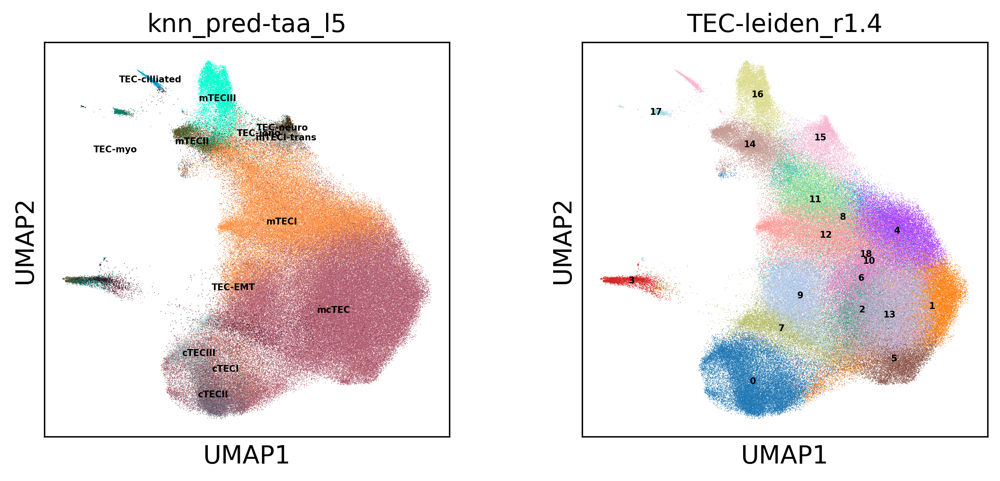

In [32]:
sc.pl.umap(tecs_xen_filt, color = ['knn_pred-taa_l5', 'TEC-leiden_r1.4'], legend_loc = 'on data', legend_fontsize = 5)

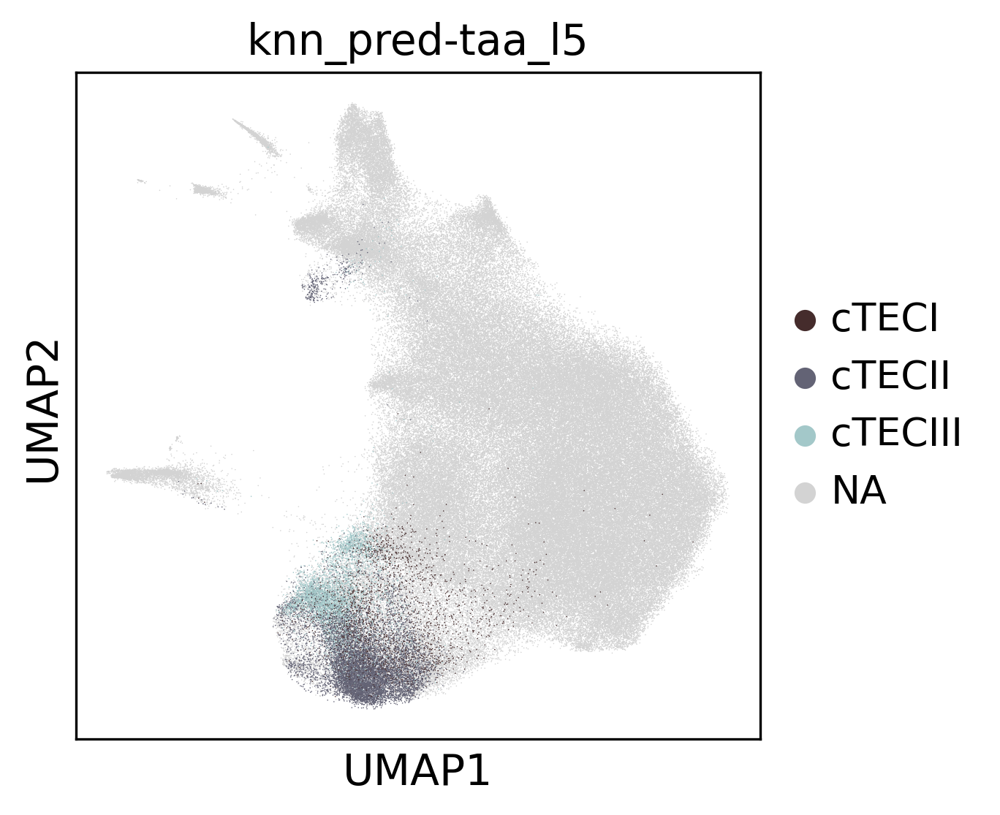

In [64]:
sc.pl.umap(tecs_xen_filt, color = ['knn_pred-taa_l5'], groups = ['cTECI', 'cTECII', 'cTECIII'])

In [41]:
tecs_xen_filt.obs['TEC_anno'] = tecs_xen_filt.obs.apply(lambda x: 'cTEC' if x['TEC-leiden_r1.4'] == '0' else
                                                    'cTEC' if x['knn_pred-taa_l5']in ['cTECI', 'cTECII', 'cTECIII'] else
                                                     'TEC-EMT' if x['TEC-leiden_r1.4'] == '3' else
                                                    'mTECII' if x['TEC-leiden_r1.4'] == '14' else
                                                    x['knn_pred-taa_l5'], axis = 1)

In [68]:
tecs_xen_filt.obs['TEC_anno2'] = tecs_xen_filt.obs.apply(lambda x: 'cTEC' if x['TEC-leiden_r1.4'] == '0' else
                                                    'c-mcTEC' if x['knn_pred-taa_l5']in ['cTECI', 'cTECII', 'cTECIII'] else
                                                     'TEC-EMT' if x['TEC-leiden_r1.4'] == '3' else
                                                    'mTECII' if x['TEC-leiden_r1.4'] == '14' else
                                                    x['knn_pred-taa_l5'], axis = 1)

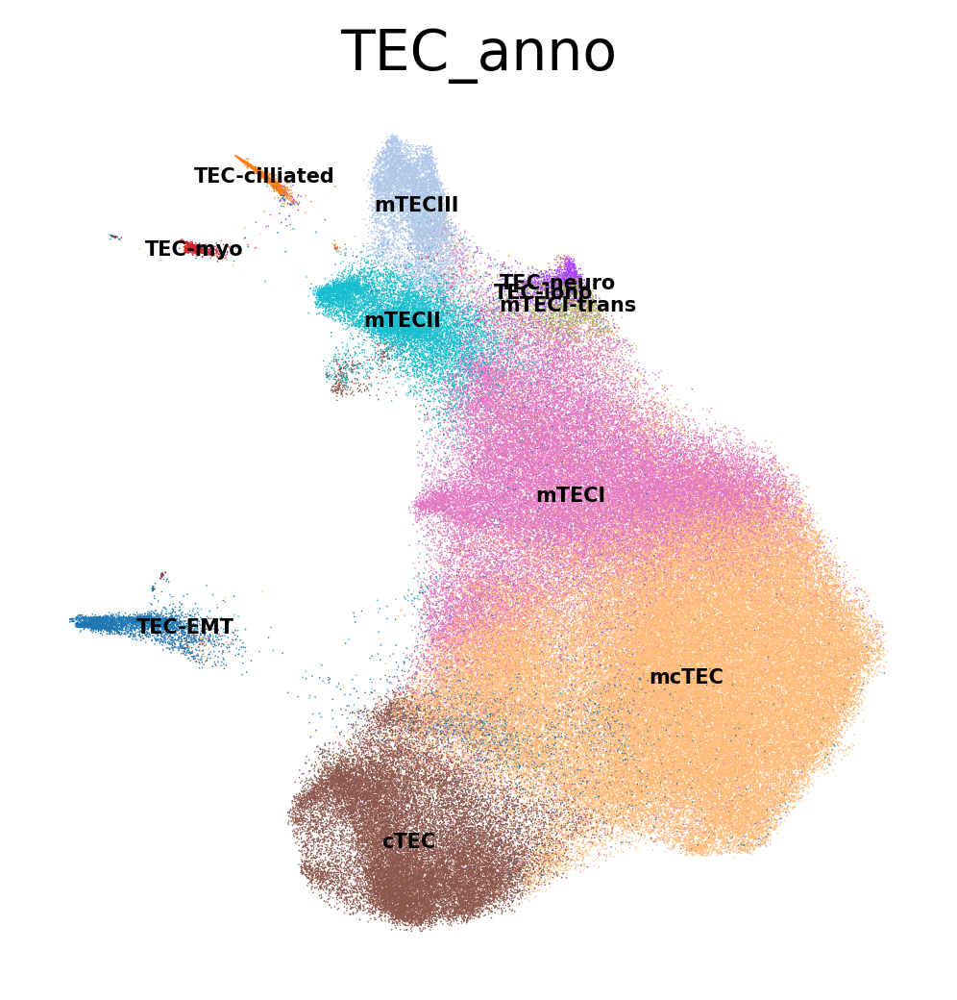

In [43]:
sc.pl.umap(tecs_xen_filt, color = ['TEC_anno'], legend_loc = 'on data', legend_fontsize = 5, frameon = False)

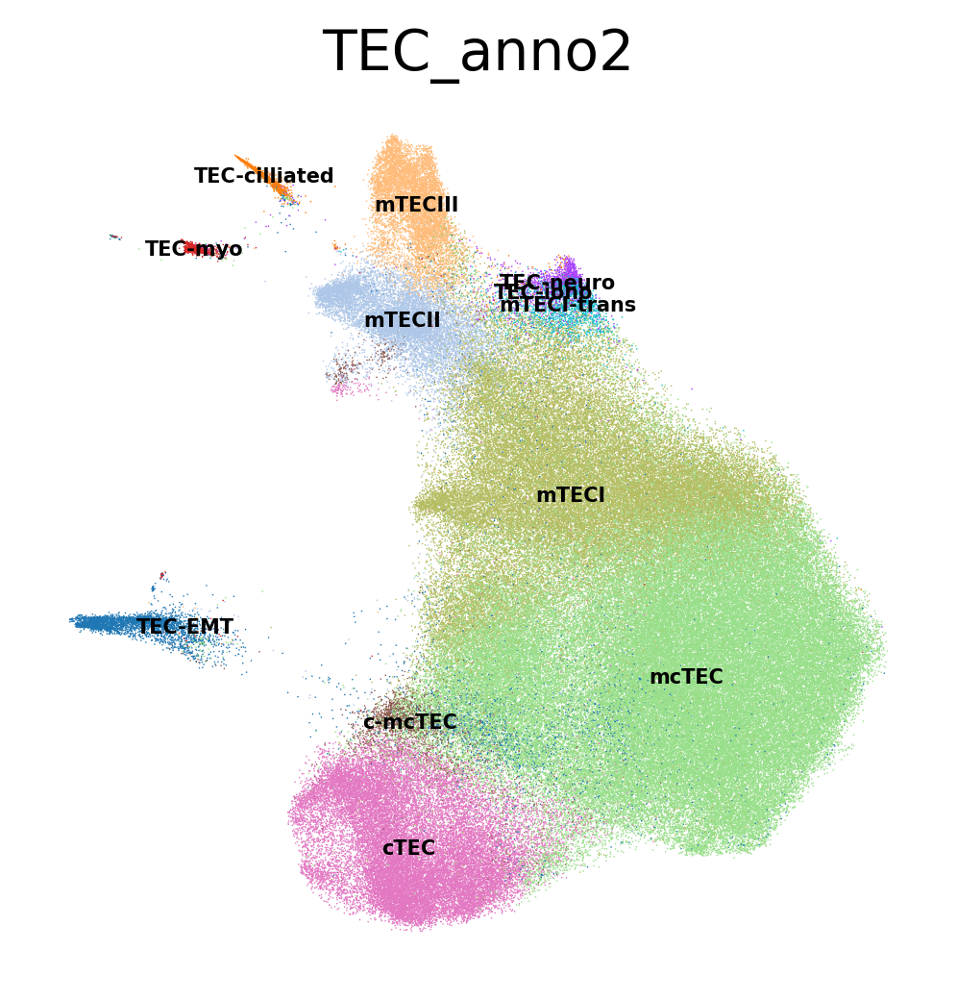

In [69]:
sc.pl.umap(tecs_xen_filt, color = ['TEC_anno2'], legend_loc = 'on data', legend_fontsize = 5, frameon = False)

In [70]:
tecs_xen_filt.obs['TEC_anno2'].value_counts()

TEC_anno2
mcTEC            103550
mTECI             50622
cTEC              26864
mTECII            10487
mTECIII            7740
TEC-EMT            6527
c-mcTEC            2097
mTECI-trans        1878
TEC-neuro          1553
TEC-cilliated      1390
TEC-myo            1006
TEC-iono            242
Name: count, dtype: int64

In [44]:
def scanpy_markers2(adata, cluster = 'leiden', group = None, pval_cutoff = None, log2fc_min = None, 
                    method = 't-test_overestim_var', use_raw = False, embed = 'X_scVI'):
    sc.tl.rank_genes_groups(adata=adata, groupby = cluster, method = method, use_raw = use_raw)
    de_df = sc.get.rank_genes_groups_df(adata=adata, group=group, pval_cutoff=pval_cutoff, log2fc_min=log2fc_min)
    sc.tl.dendrogram(adata,groupby = cluster, use_rep = embed)
    sc.pl.rank_genes_groups_dotplot (adata, n_genes = 5)
    return de_df

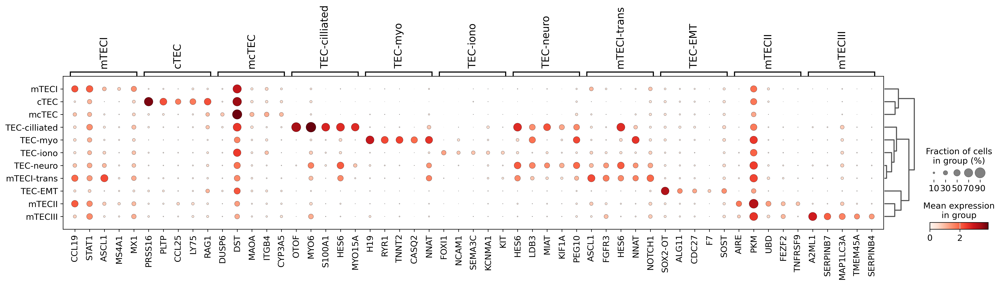

In [46]:
mrkrs_tecs  = scanpy_markers2(tecs_xen_filt, cluster = 'TEC_anno', pval_cutoff = 0.05, log2fc_min = 0.5)

In [62]:
tecs_xen_filt.obs[['TEC_anno']].to_csv(f'{data_path}/xenium/ThyAge_xenium_scarches_2025-04-09_TEC_manual_anno.csv')

In [71]:
tecs_xen_filt.obs[['TEC_anno2']].to_csv(f'{data_path}/xenium/ThyAge_xenium_scarches_2025-04-09_TEC_manual_anno_v2.csv')